# GraphRAG + VLM assembly guidance

This notebook walks through the pipeline step by step. The reusable code lives in `src/thesis/`, and the notebook calls it.

| Role | Component | Implementation |
|---|---|---|
| **Brain** | GraphRAG over the manual, stored as triples in Neo4j | `thesis.knowledge` |
| **Eyes** | `qwen3-vl:2b` via Ollama + LangChain | `thesis.vision` |
| **Voice** | Messages and markings for the worker, plus the communication log | `thesis.pipeline`, `thesis.ui` |

Every cycle:
1. The VLM looks at the frame (egocentric view), considers only the pegboard and the cylinder, and reports **observed triples**.
2. GraphRAG matches the observed triples against each step's **expected triple** and returns the current step, match/no match, and the guidance, error or success text. That text is stored **in the graph**: the VLM never invents a recommendation.
3. The worker sees the message, plus markings for the part to pick and the position to place it.

**Prerequisites:** Neo4j running (`scripts/start_neo4j.sh`), Ollama serving `qwen3-vl:2b`, and the test frames created (`python scripts/make_test_frames.py`).

In [1]:
import glob
import json
import os
import time

import cv2
import numpy as np
from IPython.display import Image, Markdown, display

from thesis.config import PROJECT_ROOT, load_settings
from thesis.knowledge import ontology as onto
from thesis.knowledge.graph_store import build_graph, connect
from thesis.knowledge.graphrag import AssemblyGraphRAG
from thesis.pipeline.comm_log import CommLog
from thesis.pipeline.guidance import GuidanceSystem
from thesis.ui.dashboard import DashboardRenderer
from thesis.vision.perception import GROUNDING_PROMPT, SYSTEM_PROMPT, Perceiver
from thesis.vision.vlm import VLMClient, encode_image

os.chdir(PROJECT_ROOT)
st = load_settings()


def table(rows, cols):
    head = "| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n"
    return Markdown(
        head + "\n".join("| " + " | ".join(str(r[c]) for c in cols) + " |" for r in rows)
    )


print("VLM:", st["vlm"]["model"], "at", st.ollama_host, "| Neo4j:", st.neo4j_uri)

VLM: qwen3-vl:2b at http://localhost:11434 | Neo4j: bolt://localhost:7687


## 1. Ontology

**Schema (T-Box):** node classes and relation types. Each step's completion condition is a *reified triple* (`ExpectedRelation`), so GraphRAG can compare what the VLM observes against it directly.

In [2]:
display(
    table([{"class": k, "meaning": v} for k, v in onto.NODE_CLASSES.items()], ["class", "meaning"])
)
display(
    table(
        [
            {"relation": k, "domain": d, "range": r, "meaning": m}
            for k, (d, r, m) in onto.RELATION_TYPES.items()
        ],
        ["relation", "domain", "range", "meaning"],
    )
)
display(
    table(
        [{"predicate": k, "meaning": v} for k, v in onto.OBSERVABLE_PREDICATES.items()],
        ["predicate", "meaning"],
    )
)

| class | meaning |
|---|---|
| Task | An assembly task the worker must complete. |
| Step | One ordered instruction of the task, taken from the worker manual. |
| Action | An atomic operation performed in a step (CHECK, PICK, PLACE). |
| Part | A physical object involved in the assembly. |
| Position | A named location on the pegboard (3x3 grid). |
| Workspace | The area in front of the worker seen by the egocentric camera. |
| ExpectedRelation | Reified triple (subject, predicate, object) that must be observed for a step to be complete. |
| ErrorCondition | An observed triple pattern that counts as a wrong move in a step. |

| relation | domain | range | meaning |
|---|---|---|---|
| HAS_STEP | Task | Step | The task consists of this step. |
| FIRST_STEP | Task | Step | The step the task starts with. |
| NEXT | Step | Step | The step that follows. |
| PERFORMS | Step | Action | The step performs this action (ordered by 'seq'). |
| ACTS_ON | Step | Part | The part the worker handles or checks in this step. |
| TARGETS | Step | Position | The position the part must end up in. |
| EXPECTS | Step | ExpectedRelation | The triple that must hold when the step is done. |
| HAS_ERROR | Step | ErrorCondition | A wrong move that can happen in this step. |
| HAS_GOAL | Task | ExpectedRelation | The triple that defines a completed assembly. |
| SUBJECT | ExpectedRelation|ErrorCondition | Part | Subject of the reified triple. |
| OBJECT | ExpectedRelation | Part|Position|Workspace | Object of the reified triple. |
| HAS_POSITION | Part | Position | The pegboard offers this position. |
| MUST_BE_PLACED_AT | Part | Position | Goal placement of a part (from the manual). |
| LOCATED_IN | Part | Workspace | The part is expected in the workspace. |

| predicate | meaning |
|---|---|
| IS_PRESENT | Part is visible in the workspace (object = 'Workspace'). |
| PLACED_AT | Part sits on the pegboard at a Position (object = position id). |
| OFF_PEGBOARD | Part is visible but not on the pegboard (object = 'Workspace'). |

**Instances (A-Box):** the worker manual written as triples.

| # | Manual instruction | Expected triple (what the VLM must see) |
|---|---|---|
| 1 | Check for green pegboard. | `(GreenPegboard, IS_PRESENT, Workspace)` |
| 2 | Check for yellow cylinder. | `(YellowCylinder, IS_PRESENT, Workspace)` |
| 3 | Pick up the yellow cylinder and place on the center of the pegboard. | `(YellowCylinder, PLACED_AT, center)` |

Wrong move (step 3): `(YellowCylinder, PLACED_AT, x)` with `x != center`, which is error `E3_WRONG_POSITION`.

In [3]:
for s, p, o in onto.manual_triples():
    print(f"({s})-[:{p}]->({o})")

(peg_assembly)-[:HAS_STEP]->(S1)
(peg_assembly)-[:FIRST_STEP]->(S1)
(S1)-[:PERFORMS]->(CHECK)
(S1)-[:ACTS_ON]->(GreenPegboard)
(S1)-[:EXPECTS]->((GreenPegboard, IS_PRESENT, Workspace))
(peg_assembly)-[:HAS_STEP]->(S2)
(S1)-[:NEXT]->(S2)
(S2)-[:PERFORMS]->(CHECK)
(S2)-[:ACTS_ON]->(YellowCylinder)
(S2)-[:EXPECTS]->((YellowCylinder, IS_PRESENT, Workspace))
(peg_assembly)-[:HAS_STEP]->(S3)
(S2)-[:NEXT]->(S3)
(S3)-[:PERFORMS]->(PICK)
(S3)-[:PERFORMS]->(PLACE)
(S3)-[:ACTS_ON]->(YellowCylinder)
(S3)-[:TARGETS]->(center)
(S3)-[:EXPECTS]->((YellowCylinder, PLACED_AT, center))
(S3)-[:HAS_ERROR]->(E3_WRONG_POSITION)
(GreenPegboard)-[:HAS_POSITION]->(top_left)
(GreenPegboard)-[:HAS_POSITION]->(top_center)
(GreenPegboard)-[:HAS_POSITION]->(top_right)
(GreenPegboard)-[:HAS_POSITION]->(middle_left)
(GreenPegboard)-[:HAS_POSITION]->(center)
(GreenPegboard)-[:HAS_POSITION]->(middle_right)
(GreenPegboard)-[:HAS_POSITION]->(bottom_left)
(GreenPegboard)-[:HAS_POSITION]->(bottom_center)
(GreenPegboard)-[:H

## 2. Build the knowledge graph in Neo4j

In [4]:
driver = connect(st)
print(build_graph(driver, st["graphrag"]["database"], reset=True))
with driver.session() as s:
    rows = s.run("""MATCH (t:Task)-[:HAS_STEP]->(s:Step)-[:EXPECTS]->(e:ExpectedRelation)
                    OPTIONAL MATCH (s)-[:ACTS_ON]->(p:Part)
                    OPTIONAL MATCH (s)-[:TARGETS]->(pos:Position)
                    RETURN s.order AS step, s.instruction AS instruction, e.description AS expects,
                           p.id AS acts_on, pos.id AS target ORDER BY step""").data()
table(rows, ["step", "instruction", "expects", "acts_on", "target"])

{'nodes': 23, 'relationships': 38}


| step | instruction | expects | acts_on | target |
|---|---|---|---|---|
| 1 | Check for green pegboard. | (GreenPegboard)-[:IS_PRESENT]->(Workspace) | GreenPegboard | None |
| 2 | Check for yellow cylinder. | (YellowCylinder)-[:IS_PRESENT]->(Workspace) | YellowCylinder | None |
| 3 | Pick up the yellow cylinder and place on the center of the pegboard. | (YellowCylinder)-[:PLACED_AT]->(center) | YellowCylinder | center |

## 3. The VLM as eyes: design measurements

`qwen3-vl:2b` in Ollama is the **thinking** variant. With thinking on, it often reasons until the token limit and returns no answer at all. The next cell measures this on two frames.

In [5]:
import requests


def raw_call(path, prompt, think_prefill):
    b64 = encode_image(cv2.imread(path), 768, 85)
    msgs = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": prompt, "images": [b64]},
    ]
    if think_prefill:
        msgs.append({"role": "assistant", "content": "<think>\n\n</think>\n\n"})
    t = time.perf_counter()
    body = {
        "model": st["vlm"]["model"],
        "stream": False,
        "messages": msgs,
        "options": {"temperature": 0, "num_predict": 1500},
    }
    if think_prefill:
        body["think"] = (
            False  # the pipeline sends both: think=false AND the empty <think></think> prefill
        )
    r = requests.post(f"{st.ollama_host}/api/chat", json=body).json()
    return {
        "ms": round((time.perf_counter() - t) * 1000),
        "tokens": r["eval_count"],
        "done": r["done_reason"],
        "answer": " ".join(r["message"]["content"].split())[:90] or "(none: still thinking)",
    }


rows = []
for f in ["data/test_frames/01_success_ref.jpg", "data/test_frames/06_scene_wrong_top_left.jpg"]:
    for mode, pre in [("thinking", False), ("no-think prefill", True)]:
        rows.append(
            {"frame": os.path.basename(f), "mode": mode, **raw_call(f, GROUNDING_PROMPT, pre)}
        )
table(rows, ["frame", "mode", "ms", "tokens", "done", "answer"])

| frame | mode | ms | tokens | done | answer |
|---|---|---|---|---|---|
| 01_success_ref.jpg | thinking | 3482 | 1500 | length | (none: still thinking) |
| 01_success_ref.jpg | no-think prefill | 294 | 72 | stop | ```json [ {"bbox_2d": [1, 1, 997, 996], "label": "pegboard"}, {"bbox_2d": [422, 417, 567,  |
| 06_scene_wrong_top_left.jpg | thinking | 3490 | 1500 | length | (none: still thinking) |
| 06_scene_wrong_top_left.jpg | no-think prefill | 302 | 76 | stop | ```json [ {"bbox_2d": [314, 200, 679, 850], "label": "pegboard"}, {"bbox_2d": [364, 275, 4 |

With `think: false` **and** an empty `<think></think>` assistant prefill, the model answers directly in about 0.2–0.3 s. The pipeline uses this (`vlm.disable_thinking: true`). The prefill without `think: false` was **not** reliable in testing: the model sometimes started thinking anyway. With both, 88 of 88 calls on the test frames answered directly. If a reply is ever unusable, the perceiver raises `PerceptionError`: the dashboard shows a system error and keeps the last valid guidance instead of guessing.

The pipeline makes two VLM calls per frame:
1. **Presence**, constrained to a JSON schema: is each object visible?
2. **Grounding**, the native Qwen `bbox_2d` output: where is it? The boxes are precise, but the model also invents boxes for objects that are absent, so a box is only used when the presence call says the object is visible.

The grid cell is computed from the boxes. The VLM's own grid answer is logged next to it for comparison.

### Perception accuracy on the synthetic test frames

In [6]:
TRUTH = {  # (pegboard visible, cylinder visible, cylinder grid cell or None)
    "01_success_ref.jpg": (True, True, "center"),
    "02_wrong_top_left.jpg": (True, True, "top_left"),
    "03_empty_board.jpg": (True, False, None),
    "04_scene_success.jpg": (True, True, "center"),
    "05_scene_cylinder_off_board.jpg": (True, True, None),
    "06_scene_wrong_top_left.jpg": (True, True, "top_left"),
    "07_scene_no_pegboard.jpg": (False, False, None),
}
vlm = VLMClient(st["vlm"]["model"], st.ollama_host, st["vlm"])
perceiver = Perceiver(vlm, st["vlm"]["max_image_side"], st["vlm"]["jpeg_quality"])
perceiver.perceive(np.full((64, 64, 3), 127, np.uint8))  # warm-up
graphrag = AssemblyGraphRAG(driver, st)
graphrag.verify([])
rows, hits = [], {"presence": 0, "geometry": 0, "vlm_grid": 0}
for name, (peg, cyl, pos) in TRUTH.items():
    o = perceiver.perceive(cv2.imread(f"data/test_frames/{name}"))
    vlm_pos = None if o.vlm_grid_position == "none" else o.vlm_grid_position
    hits["presence"] += (o.pegboard_visible, o.cylinder_visible) == (peg, cyl)
    hits["geometry"] += o.cylinder_position == pos
    hits["vlm_grid"] += vlm_pos == pos
    d = graphrag.verify(o.triples())
    rows.append(
        {
            "frame": name,
            "truth cell": pos,
            "geometry cell": o.cylinder_position,
            "VLM's own cell": vlm_pos,
            "presence ok": (o.pegboard_visible, o.cylinder_visible) == (peg, cyl),
            "VLM ms": round(sum(c.wall_ms for c in o.calls.values())),
            "GraphRAG": d.status,
            "worker message": d.message,
        }
    )
display(table(rows, list(rows[0])))
n = len(TRUTH)
print(
    f"presence correct {hits['presence']}/{n} | grid cell from boxes {hits['geometry']}/{n} | "
    f"VLM's own grid answer {hits['vlm_grid']}/{n}"
)

| frame | truth cell | geometry cell | VLM's own cell | presence ok | VLM ms | GraphRAG | worker message |
|---|---|---|---|---|---|---|---|
| 01_success_ref.jpg | center | center | center | True | 387 | success | Assembly complete: the yellow cylinder is placed on the center of the green pegboard. |
| 02_wrong_top_left.jpg | top_left | top_left | top_left | True | 422 | error | Wrong move: the yellow cylinder is at the top left position. Move it to the center of the green pegboard. |
| 03_empty_board.jpg | None | None | None | True | 423 | in_progress | Step 2: Check for the yellow cylinder. It must be visible in the workspace. |
| 04_scene_success.jpg | center | center | center | True | 404 | success | Assembly complete: the yellow cylinder is placed on the center of the green pegboard. |
| 05_scene_cylinder_off_board.jpg | None | None | None | True | 416 | in_progress | Step 3: Pick up the yellow cylinder and place it on the center of the green pegboard. |
| 06_scene_wrong_top_left.jpg | top_left | top_left | top_center | True | 393 | error | Wrong move: the yellow cylinder is at the top left position. Move it to the center of the green pegboard. |
| 07_scene_no_pegboard.jpg | None | None | None | True | 160 | in_progress | Step 1: Check for the green pegboard. It must be visible in the workspace. |

presence correct 7/7 | grid cell from boxes 7/7 | VLM's own grid answer 6/7


## 4. GraphRAG: natural language ⇄ Cypher (the VLM used as a plain LLM)

`AssemblyGraphRAG.ask()` is a LangChain chain: the VLM writes Cypher from the question, Neo4j runs it read-only, and the VLM phrases the rows as an answer. The questions below are **not** the few-shot examples in the prompt. The live loop does not depend on this path: it uses the fixed `verify()` query.

In [7]:
EVAL = [
    ("What is the first step?", "green pegboard"),
    ("What is the step after step 1?", "yellow cylinder"),
    ("What comes after step 2?", "center"),
    ("Where must the yellow cylinder be placed?", "center"),
    ("Which part does step 1 check?", "green pegboard"),
    ("Which part does step 2 check?", "yellow cylinder"),
    ("What triple must be observed to finish step 3?", "PLACED_AT"),
    ("What actions does step 3 perform?", "pick"),
    ("How many steps does the task have?", "3"),
    ("What can go wrong in step 3?", "not at the center"),
]
rows, ok = [], 0
for q, must in EVAL:
    o = graphrag.ask(q)
    hit = must.lower() in json.dumps(o["rows"], default=str).lower()
    ok += hit
    rows.append(
        {
            "question": q,
            "cypher": f"`{o['cypher'][:90]}`",
            "rows correct": hit,
            "answer": o["answer"][:90],
            "ms": round(o["t_total_ms"]),
        }
    )
display(table(rows, list(rows[0])))
print(f"text-to-Cypher retrieval correct: {ok}/{len(EVAL)}")

| question | cypher | rows correct | answer | ms |
|---|---|---|---|---|
| What is the first step? | `MATCH (:Task)-[:FIRST_STEP]->(s:Step) RETURN s.order, s.instruction` | True | The first step is to check for green pegboard. | 191 |
| What is the step after step 1? | `MATCH (:Step {order: 1})-[:NEXT]->(s:Step) RETURN s.order, s.instruction` | True | The step after step 1 is "Check for yellow cylinder." | 160 |
| What comes after step 2? | `MATCH (:Step {order: 2})-[:NEXT]->(s:Step) RETURN s.order, s.instruction` | True | Step 2 is "Pick up the yellow cylinder and place on the center of the pegboard." The next  | 226 |
| Where must the yellow cylinder be placed? | `MATCH (:Part {id: 'YellowCylinder'})-[:MUST_BE_PLACED_AT]->(p:Position) RETURN p.name` | True | The yellow cylinder must be placed at the center. | 160 |
| Which part does step 1 check? | `MATCH (:Step {order: 1})-[:ACTS_ON]->(p:Part) RETURN p.name, p.id, p.shape, p.vlm_label, p` | True | Step 1 checks the part of the database row where the name is 'green pegboard'. | 214 |
| Which part does step 2 check? | `MATCH (:Step {order: 2})-[:ACTS_ON]->(p:Part) RETURN p.name` | True | Step 2 checks the part "yellow cylinder". | 155 |
| What triple must be observed to finish step 3? | `MATCH (:Step {order: 3})-[:EXPECTS]->(e:ExpectedRelation) RETURN e.subject, e.predicate, e` | True | The triple that must be observed to finish step 3 is: e.subject = 'YellowCylinder', e.pred | 230 |
| What actions does step 3 perform? | `MATCH (:Step {order: 3})-[:PERFORMS]->(a:Action) RETURN a.verb, a.id` | True | Step 3 performs the action of placing. | 162 |
| How many steps does the task have? | `MATCH (t:Task)-[:HAS_STEP]->(s:Step) RETURN COUNT(s) AS steps_count WHERE t.id = 'task_id'` | False | I don't know: the knowledge graph returned no result. | 392 |
| What can go wrong in step 3? | `MATCH (:Step {order: 3})-[:HAS_ERROR]->(e:ErrorCondition) RETURN e.description` | True | The yellow cylinder is on the pegboard but not at the center. | 153 |

text-to-Cypher retrieval correct: 9/10


## 5. End-to-end cycle and dashboard render

reference image vs graph goal: success


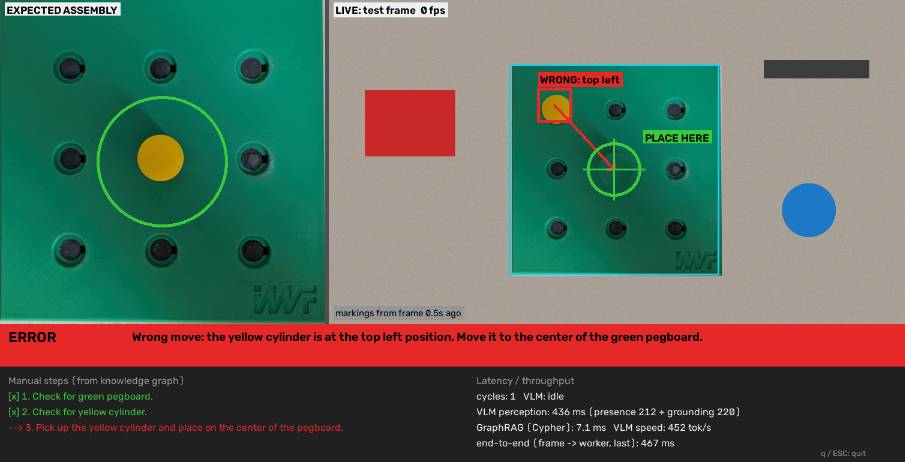

In [8]:
log = CommLog("logs", "notebook_" + time.strftime("%Y-%m-%d_%H-%M-%S"))
system = GuidanceSystem(perceiver, graphrag, log)
renderer = DashboardRenderer(
    cv2.imread(st["reference_image"]),
    st["dashboard"]["view_height"],
    st["dashboard"]["panel_height"],
)
renderer.ref_result = system.run_cycle(cv2.imread(st["reference_image"]), 0, time.perf_counter())
print("reference image vs graph goal:", renderer.ref_result.decision.status)
frame = cv2.imread("data/test_frames/06_scene_wrong_top_left.jpg")
res = system.run_cycle(frame, 1, time.perf_counter())
img = renderer.render(frame, res, "test frame", 1, False)
system.log_delivery(res, time.perf_counter())
renderer.delivered(res)
img = renderer.render(frame, res, "test frame", 1, False)
display(
    Image(
        data=cv2.imencode(
            ".jpg", cv2.resize(img, None, fx=0.6, fy=0.6), [cv2.IMWRITE_JPEG_QUALITY, 70]
        )[1].tobytes()
    )
)

## 6. Latency and throughput benchmark

20 cycles on the demo sequence (4 frames per scene: no board, board only, cylinder off the board, wrong position, success). Every message goes into the communication log (`communication.md`/`.csv`).

In [9]:
frames = [cv2.imread(f) for f in sorted(glob.glob("data/demo_sequence/*.jpg")) for _ in range(4)]
for i, fr in enumerate(frames, start=2):
    r = system.run_cycle(fr, i, time.perf_counter())
    system.log_delivery(r, time.perf_counter())
summary = log.close()
rows = [
    {
        "hop": k,
        "n": v["n"],
        "mean ms": f"{v['mean']:.1f}",
        "median ms": f"{v['median']:.1f}",
        "p95 ms": f"{v['p95']:.1f}",
        "max ms": f"{v['max']:.1f}",
    }
    for k, v in summary.items()
    if k != "VLM throughput"
]
display(table(rows, list(rows[0])))
t = summary["VLM throughput"]
print(
    f"VLM: {t['requests']} requests, {t['requests_per_s']:.2f} requests/s, "
    f"{t['mean_output_tokens_per_s']:.0f} output tokens/s"
)
print("log:", log.md_path)

| hop | n | mean ms | median ms | p95 ms | max ms |
|---|---|---|---|---|---|
| VLM → GraphRAG | 21 | 325.6 | 355.8 | 422.8 | 435.6 |
| GraphRAG → VLM | 21 | 5.7 | 5.5 | 10.0 | 11.8 |
| VLM → Worker | 21 | 1.1 | 0.0 | 0.0 | 23.9 |
| end-to-end (frame → worker) | 21 | 332.9 | 361.8 | 427.6 | 467.1 |

VLM: 40 requests, 5.59 requests/s, 456 output tokens/s
log: logs/notebook_2026-11-21_16-33-47/communication.md


In [10]:
# the first rows of the communication log
print("\n".join(log.md_path.read_text().splitlines()[4:13]))

| cycle | time | sender → receiver | message | hop latency (ms) | end-to-end (ms) | details |
|---:|---|---|---|---:|---:|---|
| 0 | 16:33:48.161 | VLM → GraphRAG | Pegboard visible; yellow cylinder on the pegboard at center. Triples: [(GreenPegboard, IS_PRESENT, Workspace), (YellowCylinder, IS_PRESENT, Workspace), (YellowCylinder, PLACED_AT, center)] | 376.5 | 376.5 | presence: 169 ms, 41 tok @ 444 tok/s; grounding: 205 ms, 72 tok @ 449 tok/s; VLM's own grid answer: center |
| 0 | 16:33:48.167 | GraphRAG → VLM | All 3 expected triples observed. Goal state reached. | 6.2 | 383.0 | Cypher verify; status=success |
| 1 | 16:33:48.629 | VLM → GraphRAG | Pegboard visible; yellow cylinder on the pegboard at top left. Triples: [(GreenPegboard, IS_PRESENT, Workspace), (YellowCylinder, IS_PRESENT, Workspace), (YellowCylinder, PLACED_AT, top_left)] | 435.6 | 435.6 | presence: 212 ms, 36 tok @ 451 tok/s; grounding: 220 ms, 76 tok @ 452 tok/s; VLM's own grid answer: top_center |
| 1 | 16:33:48.636

## 7. Limitations and next steps

- **Test frames are synthetic** (made from the reference photo). Accuracy on real egocentric D435 frames (hands, motion blur, perspective, lighting) still has to be measured.
- **Grid cells come from axis-aligned boxes.** Under strong perspective or rotation of the board, cells near the edges may be misassigned. A homography from the board corners would fix this.
- **"Placed" versus "held above the center":** a 2D box cannot tell them apart. The D435 depth stream could check that the cylinder touches the board.
- **No debouncing:** a single wrong VLM answer changes the status for one cycle. Requiring N identical results before switching state would trade latency for stability.
- **Text-to-Cypher with a 2B model** is only partly reliable (see section 4). That is why per-cycle guidance uses the fixed `verify()` query.

In [11]:
driver.close()